# 03 · Estructura de vecindad y autocorrelación espacial

| | |
|---|---|
| **Pregunta** | ¿El acceso a canales financieros se distribuye aleatoriamente entre distritos o forma agrupamientos, en particular zonas contiguas de bajo acceso ("desiertos financieros")? |
| **Variable** | y = √acceso_eb (tasa suavizada por Bayes empírico, notebook 02). |
| **Métodos** | Matrices de contigüidad (Reina, Torre), k vecinos más cercanos y banda de distancia; I de Moran y C de Geary globales con inferencia por permutación; LISA (Anselin, 1995) con control FDR; Getis-Ord Gi*; Moran bivariado global y local. |
| **Salidas** | `outputs/figuras/03_*.png` · `data/processed/lisa_acceso.csv`. |

In [1]:
from pathlib import Path
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from esda import Geary, Moran, Moran_BV, Moran_Local, Moran_Local_BV, G_Local
from libpysal import weights

warnings.filterwarnings("ignore")
np.random.seed(2026)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
FIG = ROOT / "outputs" / "figuras"
CRS_METRICO = "EPSG:32717"
PERM = 999   # permutaciones para la inferencia por aleatorización

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Datos

In [2]:
g = gpd.read_file(DATA / "geobanca_norte.gpkg", layer="distritos").to_crs(CRS_METRICO)
aede = pd.read_csv(DATA / "base_aede.csv", dtype={"ubigeo": str})[["ubigeo", "acceso_eb"]]
g = g.merge(aede, on="ubigeo", how="left").reset_index(drop=True)
g["y"] = np.sqrt(g["acceso_eb"])
deps = g.dissolve("departamento").reset_index()[["departamento", "geometry"]]
print(f"{len(g)} distritos | y: media {g['y'].mean():.2f}, desv. {g['y'].std():.2f}")

327 distritos | y: media 10.28, desv. 3.64


## 2. Matrices de pesos espaciales

Se comparan cuatro definiciones de vecindad. Todas se estandarizan por filas (cada fila suma 1), de modo que el
rezago espacial `W·y` es el promedio de los vecinos.

- **Reina (Queen):** vecinos si comparten al menos un vértice.
- **Torre (Rook):** vecinos si comparten un borde.
- **k vecinos más cercanos (k = 6):** los 6 centroides más cercanos; todos tienen el mismo número de vecinos.
- **Banda de distancia:** vecinos a menos de *d* km, con *d* el mínimo que no deja distritos aislados.

In [3]:
cent = g.copy(); cent["geometry"] = g.geometry.centroid
d_min = weights.min_threshold_distance(np.column_stack([cent.geometry.x, cent.geometry.y]))

W = {
    "Reina": weights.Queen.from_dataframe(g, use_index=False),
    "Torre": weights.Rook.from_dataframe(g, use_index=False),
    "kNN (k=6)": weights.KNN.from_dataframe(cent, k=6),
    f"Banda {d_min/1000:.0f} km": weights.DistanceBand.from_dataframe(cent, threshold=d_min, binary=True),
}
filas = []
for nombre, w in W.items():
    card = pd.Series(w.cardinalities)
    filas.append({"matriz": nombre, "aislados": len(w.islands), "vecinos_media": card.mean(),
                  "vecinos_min": card.min(), "vecinos_max": card.max(), "% no ceros": w.pct_nonzero})
    w.transform = "r"
pd.DataFrame(filas).set_index("matriz").round(2)

,aislados,vecinos_media,vecinos_min,vecinos_max,% no ceros
matriz,,,,,
Reina,0,5.45,1,14,1.67
Torre,0,5.33,1,13,1.63
kNN (k=6),0,6.00,6,6,1.83
Banda 43 km,0,17.83,1,41,5.45


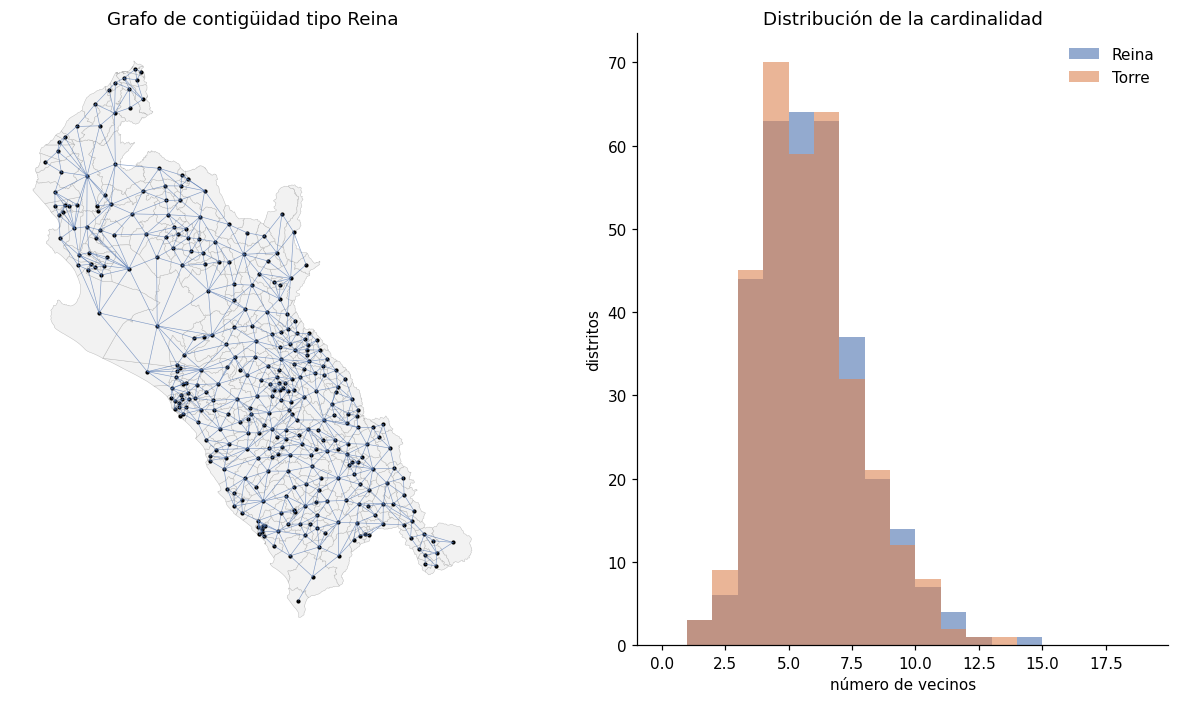

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6.5), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
g.plot(ax=ax, color="#f2f2f2", edgecolor="#bbbbbb", linewidth=0.3)
w = W["Reina"]
xy = np.column_stack([cent.geometry.x, cent.geometry.y])
for i, vecinos in w.neighbors.items():
    for j in vecinos:
        if j > i:
            ax.plot(*zip(xy[i], xy[j]), color="#4c72b0", linewidth=0.4, alpha=0.7)
ax.scatter(xy[:, 0], xy[:, 1], s=3, color="black")
ax.set_title("Grafo de contigüidad tipo Reina")
ax.set_axis_off()

ax = axes[1]
bins = np.arange(0, 20)
for nombre, color in [("Reina", "#4c72b0"), ("Torre", "#dd8452")]:
    ax.hist(pd.Series(W[nombre].cardinalities), bins=bins, alpha=0.6, color=color, label=nombre)
ax.set_xlabel("número de vecinos"); ax.set_ylabel("distritos"); ax.legend(frameon=False)
ax.set_title("Distribución de la cardinalidad")
fig.tight_layout()
fig.savefig(FIG / "03_matriz_pesos.png", bbox_inches="tight")
plt.show()

## 3. Autocorrelación global: I de Moran y C de Geary

- **I de Moran** > 0 indica agrupamiento de valores parecidos; su esperanza bajo aleatoriedad es -1/(n-1) ≈ 0.
- **C de Geary** < 1 indica autocorrelación positiva (diferencias pequeñas entre vecinos).

La significancia se obtiene por **999 permutaciones aleatorias** de los valores sobre el mapa (pseudo p-valor).

In [5]:
res = []
for nombre, w in W.items():
    mi = Moran(g["y"], w, permutations=PERM)
    gc = Geary(g["y"], w, permutations=PERM)
    res.append({"matriz": nombre, "I": mi.I, "E[I]": mi.EI, "z (perm.)": mi.z_sim, "p (perm.)": mi.p_sim,
                "C de Geary": gc.C, "p Geary": gc.p_sim})
moran_tab = pd.DataFrame(res).set_index("matriz")
moran_tab.round(3)

,I,E[I],z (perm.),p (perm.),C de Geary,p Geary
matriz,,,,,,
Reina,0.277,-0.003,8.176,0.001,0.721,0.001
Torre,0.277,-0.003,8.229,0.001,0.720,0.001
kNN (k=6),0.281,-0.003,9.743,0.001,0.736,0.001
Banda 43 km,0.264,-0.003,13.092,0.001,0.737,0.001


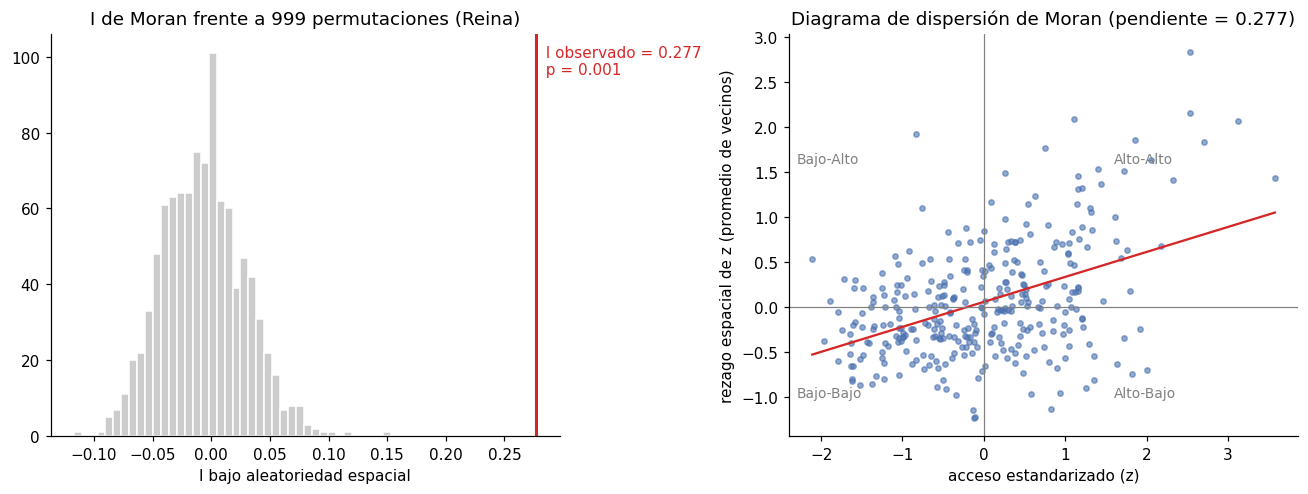

In [6]:
mi = Moran(g["y"], W["Reina"], permutations=PERM)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

ax = axes[0]
ax.hist(mi.sim, bins=40, color="#cccccc", edgecolor="white")
ax.axvline(mi.I, color="#d62728", linewidth=2)
ax.text(mi.I, ax.get_ylim()[1] * 0.9, f"  I observado = {mi.I:.3f}\n  p = {mi.p_sim:.3f}", color="#d62728")
ax.set_title("I de Moran frente a 999 permutaciones (Reina)")
ax.set_xlabel("I bajo aleatoriedad espacial")

ax = axes[1]
z = (g["y"] - g["y"].mean()) / g["y"].std()
lag = weights.lag_spatial(W["Reina"], z)
ax.scatter(z, lag, s=12, alpha=0.6, color="#4c72b0")
b = np.polyfit(z, lag, 1)
xs = np.linspace(z.min(), z.max(), 10)
ax.plot(xs, b[0] * xs + b[1], color="#d62728")
ax.axhline(0, color="grey", linewidth=0.8); ax.axvline(0, color="grey", linewidth=0.8)
for txt, (xx, yy) in {"Alto-Alto": (1.6, 1.6), "Bajo-Bajo": (-2.3, -1.0), "Bajo-Alto": (-2.3, 1.6), "Alto-Bajo": (1.6, -1.0)}.items():
    ax.text(xx, yy, txt, color="grey", fontsize=9)
ax.set_xlabel("acceso estandarizado (z)"); ax.set_ylabel("rezago espacial de z (promedio de vecinos)")
ax.set_title(f"Diagrama de dispersión de Moran (pendiente = {b[0]:.3f})")
fig.tight_layout()
fig.savefig(FIG / "03_moran_global.png", bbox_inches="tight")
plt.show()

## 4. Autocorrelación local: LISA

El I de Moran local descompone el índice global por distrito. Con 999 permutaciones condicionales se clasifica
cada distrito significativo (p < 0,05) en:

- **Alto-Alto (HH):** buen acceso rodeado de buen acceso.
- **Bajo-Bajo (LL):** poco acceso rodeado de poco acceso: **desierto financiero**, el objetivo comercial del proyecto.
- **Bajo-Alto (LH) / Alto-Bajo (HL):** atípicos espaciales.

Como se hacen 327 pruebas a la vez, se reporta también cuántos siguen siendo significativos con la corrección
FDR (tasa de falsos descubrimientos) como prueba de robustez.

In [7]:
from esda import fdr

lisa = Moran_Local(g["y"], W["Reina"], permutations=PERM, seed=2026)
ETQ = {0: "No significativo", 1: "Alto-Alto", 2: "Bajo-Alto", 3: "Bajo-Bajo", 4: "Alto-Bajo"}
COL = {"No significativo": "#e6e6e6", "Alto-Alto": "#d7191c", "Bajo-Bajo": "#2c7bb6",
       "Bajo-Alto": "#abd9e9", "Alto-Bajo": "#fdae61"}
g["lisa_q"] = np.where(lisa.p_sim < 0.05, lisa.q, 0)
g["lisa"] = g["lisa_q"].map(ETQ)
g["lisa_p"] = lisa.p_sim
g["lisa_Ii"] = lisa.Is

umbral_fdr = fdr(lisa.p_sim, 0.05)
print(f"Umbral FDR: {umbral_fdr:.4f} -> distritos significativos con FDR: {(lisa.p_sim <= umbral_fdr).sum()}")
pd.crosstab(g["lisa"], g["departamento"], margins=True, margins_name="Total")

Umbral FDR: 0.0021 -> distritos significativos con FDR: 14


departamento,CAJAMARCA,LA LIBERTAD,LAMBAYEQUE,PIURA,TUMBES,Total
lisa,,,,,,
Alto-Alto,1,0,1,22,10,34
Alto-Bajo,5,5,0,0,0,10
Bajo-Alto,0,1,0,2,0,3
Bajo-Bajo,14,1,0,4,0,19
No significativo,107,77,37,37,3,261
Total,127,84,38,65,13,327


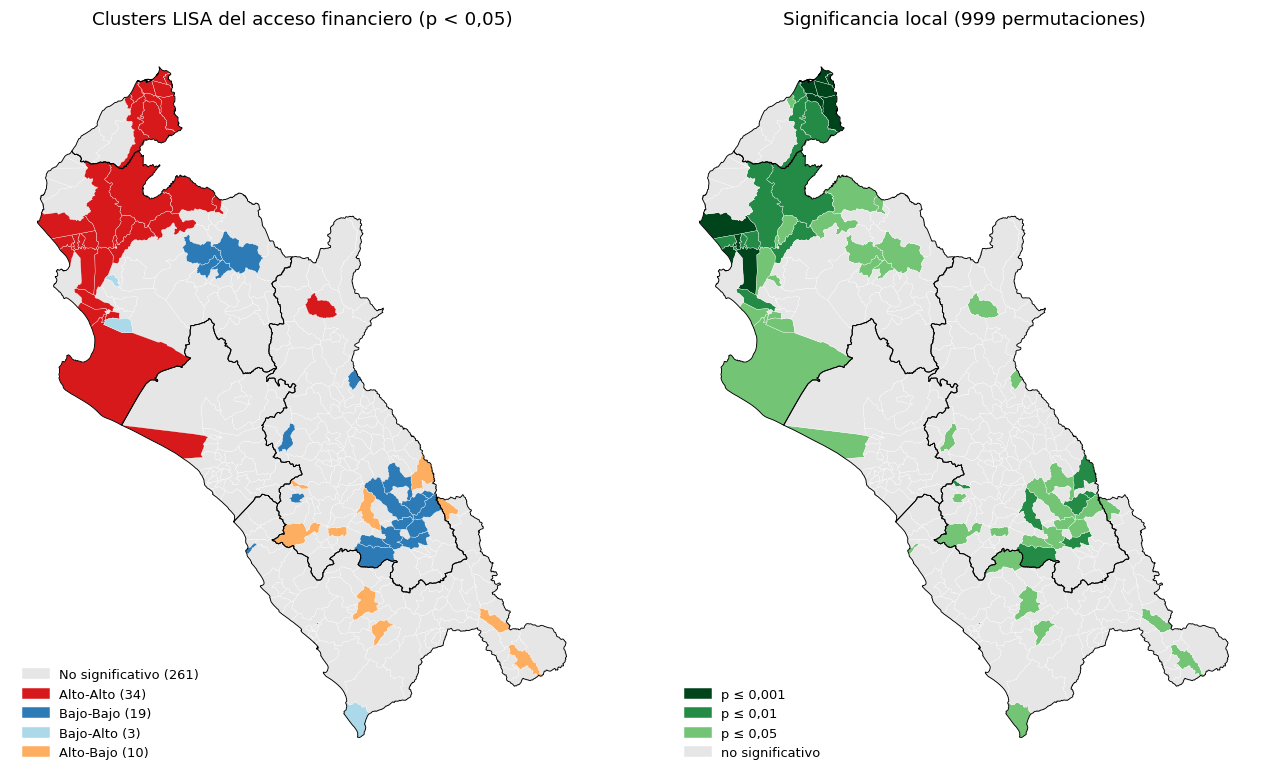

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 7), constrained_layout=True)
ax = axes[0]
for etq, color in COL.items():
    sub = g[g["lisa"] == etq]
    if len(sub):
        sub.plot(ax=ax, color=color, edgecolor="white", linewidth=0.2)
deps.boundary.plot(ax=ax, color="black", linewidth=0.6)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COL.values()],
          [f"{k} ({(g['lisa'] == k).sum()})" for k in COL], loc="lower left", frameon=False, fontsize=8.5)
ax.set_title("Clusters LISA del acceso financiero (p < 0,05)")
ax.set_axis_off()

ax = axes[1]
cortes = [0, 0.001, 0.01, 0.05, 1.0]
etiquetas_p = ["p ≤ 0,001", "p ≤ 0,01", "p ≤ 0,05", "no significativo"]
colores_p = ["#00441b", "#238b45", "#74c476", "#e6e6e6"]
g["p_clase"] = pd.cut(g["lisa_p"], cortes, labels=etiquetas_p, include_lowest=True)
for etq, color in zip(etiquetas_p, colores_p):
    sub = g[g["p_clase"] == etq]
    if len(sub):
        sub.plot(ax=ax, color=color, edgecolor="white", linewidth=0.2)
deps.boundary.plot(ax=ax, color="black", linewidth=0.6)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in colores_p], etiquetas_p,
          loc="lower left", frameon=False, fontsize=8.5)
ax.set_title("Significancia local (999 permutaciones)")
ax.set_axis_off()
fig.savefig(FIG / "03_lisa_acceso.png", bbox_inches="tight")
plt.show()

In [9]:
# Desiertos financieros: distritos Bajo-Bajo
desiertos = g[g["lisa"] == "Bajo-Bajo"].sort_values("acceso_eb")
print(f"{len(desiertos)} distritos Bajo-Bajo | {desiertos['pob_total_2025'].sum():,.0f} habitantes | "
      f"{desiertos['pob_18mas'].sum():,.0f} adultos estimados")
desiertos[["distrito", "provincia", "departamento", "pob_total_2025", "acceso_eb", "pobreza_2018", "lisa_p"]].round(2)

19 distritos Bajo-Bajo | 212,000 habitantes | 157,222 adultos estimados


,distrito,provincia,departamento,pob_total_2025,acceso_eb,pobreza_2018,lisa_p
95,GREGORIO PITA,SAN MARCOS,CAJAMARCA,5492,18.68,60.85,0.04
279,CHALACO,MORROPON,PIURA,7401,19.10,49.98,0.04
285,SANTO DOMINGO,MORROPON,PIURA,5955,19.21,40.74,0.04
25,SUCRE,CELENDIN,CAJAMARCA,5581,22.59,53.91,0.01
23,OXAMARCA,CELENDIN,CAJAMARCA,6029,33.54,81.00,0.01
1,ASUNCION,CAJAMARCA,CAJAMARCA,7544,42.13,58.25,0.04
264,PACAIPAMPA,AYABACA,PIURA,24326,49.68,67.17,0.04
260,FRIAS,AYABACA,PIURA,19849,57.83,61.37,0.04
5,JESUS,CAJAMARCA,CAJAMARCA,17951,62.58,70.50,0.05
3,COSPAN,CAJAMARCA,CAJAMARCA,6809,66.81,73.63,0.00


## 5. Extra: puntos calientes y fríos (Getis-Ord Gi*)

Gi* compara la suma local (el distrito y sus vecinos) con la esperada. A diferencia del LISA no separa atípicos,
pero es la medida más usada para comunicar "zonas frías" a un público no técnico, útil para el póster.

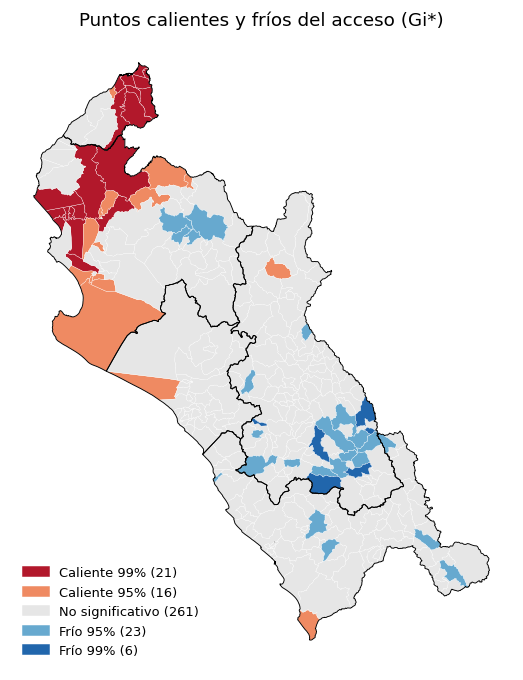

In [10]:
gi = G_Local(g["y"], W["Reina"], star=True, permutations=PERM, seed=2026)
g["gi_z"] = gi.Zs
g["gi_clase"] = np.select(
    [(gi.p_sim < 0.01) & (gi.Zs > 0), (gi.p_sim < 0.05) & (gi.Zs > 0),
     (gi.p_sim < 0.01) & (gi.Zs < 0), (gi.p_sim < 0.05) & (gi.Zs < 0)],
    ["Caliente 99%", "Caliente 95%", "Frío 99%", "Frío 95%"], default="No significativo")
COL_GI = {"Caliente 99%": "#b2182b", "Caliente 95%": "#ef8a62", "No significativo": "#e6e6e6",
          "Frío 95%": "#67a9cf", "Frío 99%": "#2166ac"}

fig, ax = plt.subplots(figsize=(6.5, 7.5))
for etq, color in COL_GI.items():
    sub = g[g["gi_clase"] == etq]
    if len(sub):
        sub.plot(ax=ax, color=color, edgecolor="white", linewidth=0.2)
deps.boundary.plot(ax=ax, color="black", linewidth=0.6)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COL_GI.values()],
          [f"{k} ({(g['gi_clase'] == k).sum()})" for k in COL_GI], loc="lower left", frameon=False, fontsize=8.5)
ax.set_title("Puntos calientes y fríos del acceso (Gi*)")
ax.set_axis_off()
fig.savefig(FIG / "03_getis_ord.png", bbox_inches="tight")
plt.show()

## 6. Dependencia bivariada: pobreza y acceso de los vecinos

El LISA bivariado relaciona la **pobreza de cada distrito** con el **acceso promedio de sus vecinos**.
Los distritos "Alto-Bajo" (pobres rodeados de poco acceso) son los más difíciles de atender: ni el propio
distrito ni su entorno tienen canales. Alto Trujillo, sin dato de pobreza 2018, se imputa con el promedio de
sus vecinos (rezago espacial).

Imputados por rezago espacial: ['ALTO TRUJILLO']
I de Moran bivariado (pobreza, acceso de los vecinos) = -0.270, p = 0.001


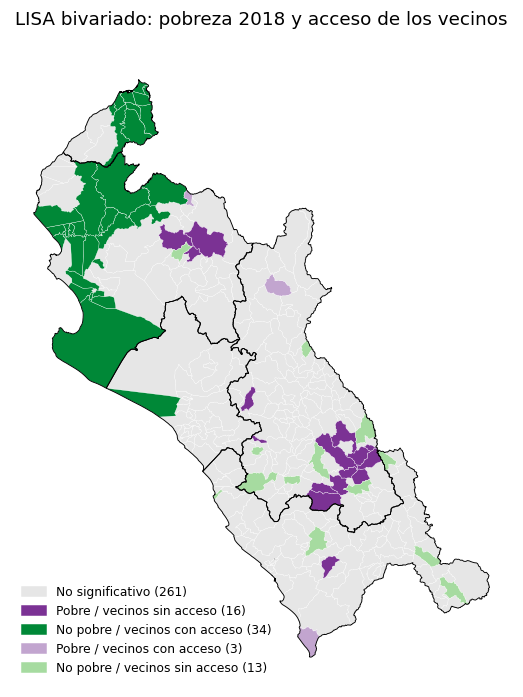

lisa_bv
No significativo                 261
No pobre / vecinos con acceso     34
Pobre / vecinos sin acceso        16
No pobre / vecinos sin acceso     13
Pobre / vecinos con acceso         3
Name: count, dtype: int64

In [11]:
pob = g["pobreza_2018"].copy()
faltan = pob.isna()
if faltan.any():
    lag_pob = weights.lag_spatial(W["Reina"], pob.fillna(pob.mean()))
    pob[faltan] = lag_pob[faltan]
    print("Imputados por rezago espacial:", g.loc[faltan, "distrito"].tolist())
g["pobreza_imp"] = pob

bv = Moran_BV(g["pobreza_imp"], g["y"], W["Reina"], permutations=PERM)
print(f"I de Moran bivariado (pobreza, acceso de los vecinos) = {bv.I:.3f}, p = {bv.p_sim:.3f}")

lbv = Moran_Local_BV(g["pobreza_imp"], g["y"], W["Reina"], permutations=PERM, seed=2026)
ETQ_BV = {0: "No significativo", 1: "Pobre / vecinos con acceso", 2: "No pobre / vecinos con acceso",
          3: "No pobre / vecinos sin acceso", 4: "Pobre / vecinos sin acceso"}
COL_BV = {"No significativo": "#e6e6e6", "Pobre / vecinos sin acceso": "#7b3294",
          "No pobre / vecinos con acceso": "#008837", "Pobre / vecinos con acceso": "#c2a5cf",
          "No pobre / vecinos sin acceso": "#a6dba0"}
g["lisa_bv"] = pd.Series(np.where(lbv.p_sim < 0.05, lbv.q, 0)).map(ETQ_BV).values

fig, ax = plt.subplots(figsize=(6.5, 7.5))
for etq, color in COL_BV.items():
    sub = g[g["lisa_bv"] == etq]
    if len(sub):
        sub.plot(ax=ax, color=color, edgecolor="white", linewidth=0.2)
deps.boundary.plot(ax=ax, color="black", linewidth=0.6)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COL_BV.values()],
          [f"{k} ({(g['lisa_bv'] == k).sum()})" for k in COL_BV], loc="lower left", frameon=False, fontsize=8)
ax.set_title("LISA bivariado: pobreza 2018 y acceso de los vecinos")
ax.set_axis_off()
fig.savefig(FIG / "03_lisa_bivariado.png", bbox_inches="tight")
plt.show()
g["lisa_bv"].value_counts()

## 7. ¿Las covariables también tienen dependencia espacial?

Si la variable respuesta y sus explicativas están autocorrelacionadas, un modelo OLS dejará residuos
autocorrelacionados. Esto anticipa la necesidad de los modelos SAR y SEM del notebook 04.

In [12]:
covs = {"acceso (y)": g["y"], "pobreza 2018": g["pobreza_imp"], "IDH 2019": g["idh_2019"].fillna(g["idh_2019"].mean()),
        "% urbana": g["pct_urbana"], "altitud": g["altitud_capital_m"].fillna(g["altitud_capital_m"].mean()),
        "log densidad": np.log1p(g["densidad_hab_km2"])}
pd.DataFrame({k: {"I de Moran": (m := Moran(v, W["Reina"], permutations=PERM)).I, "p": m.p_sim}
              for k, v in covs.items()}).T.round(3)

,I de Moran,p
acceso (y),0.277,0.001
pobreza 2018,0.692,0.001
IDH 2019,0.615,0.001
% urbana,0.646,0.001
altitud,0.857,0.001
log densidad,0.564,0.001


## 8. Exportar

In [13]:
cols = ["ubigeo", "distrito", "provincia", "departamento", "y", "acceso_eb", "lisa", "lisa_p", "lisa_Ii",
        "gi_z", "gi_clase", "lisa_bv", "pobreza_imp"]
g[cols].to_csv(DATA / "lisa_acceso.csv", index=False)
print("Guardado:", (DATA / "lisa_acceso.csv").relative_to(ROOT))

Guardado: data/processed/lisa_acceso.csv


## 9. Hallazgos para el proyecto

1. **El acceso no es aleatorio en el espacio.** I de Moran = 0,277 (p = 0,001 con 999 permutaciones) y C de Geary
   = 0,72 (p = 0,001). El resultado es casi idéntico con las cuatro matrices (I entre 0,26 y 0,28), así que no
   depende de cómo se definan los vecinos. Se adopta la matriz **Reina** para el resto del proyecto (sin
   aislados, 5,5 vecinos en promedio).
2. **Dos regímenes claros.** Hay 34 distritos Alto-Alto, casi todos en la costa de Piura y Tumbes (corredor
   Tumbes-Sullana-Piura-Paita), y **19 desiertos financieros Bajo-Bajo** con 212 mil habitantes: 14 en
   Cajamarca (Cajamarca, Celendín, San Marcos) y 4 en la sierra de Piura (Ayabaca y Morropón).
3. **Robustez.** Con corrección FDR por pruebas múltiples siguen siendo significativos 14 distritos; los núcleos
   de ambos regímenes se mantienen. Gi* confirma el mismo patrón: 37 puntos calientes y 29 fríos.
4. **Pobreza y acceso del entorno van en sentido opuesto.** I de Moran bivariado = -0,27 (p = 0,001). Hay 16
   distritos pobres rodeados de vecinos sin acceso (12 en Cajamarca): ni el distrito ni su entorno tienen canales,
   son el segmento prioritario para agentes o EOB.
5. **Las covariables están aún más autocorrelacionadas** que el acceso (pobreza 0,69, altitud 0,86, % urbana 0,65).
   Un OLS dejaría dependencia en los residuos: el notebook 04 compara OLS, SAR y SEM.